# Assignment: Data Visualization & Preprocessing
**Domain:** Healthcare / Medical Diagnosis  
**Dataset:** Stroke Prediction Dataset (Kaggle)  
**Target:** `stroke` (0 = No Stroke, 1 = Stroke)  
**Student:** Abdelrahman Ahmed Mohamed Fathallah

## Part 1: Data Loading & Initial Inspection

### 1.1 Import important libraries (pandas, numpy, matplotlib, seaborn, sklearn)

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import SMOTE

### 1.2 Load `healthcare-dataset-stroke-data.csv` into DataFrame `df`

In [2]:
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

### 1.3 Display the first 5 rows using `df.head()`

In [3]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


### 1.4 Check data types, non-null values and memory usage using `df.info()`

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


### 1.5 Statistical summary using `df.describe()`

In [5]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


## Part 2: Exploratory Data Analysis & Visualization

### 2.1 Countplot for the `stroke` column (class distribution)

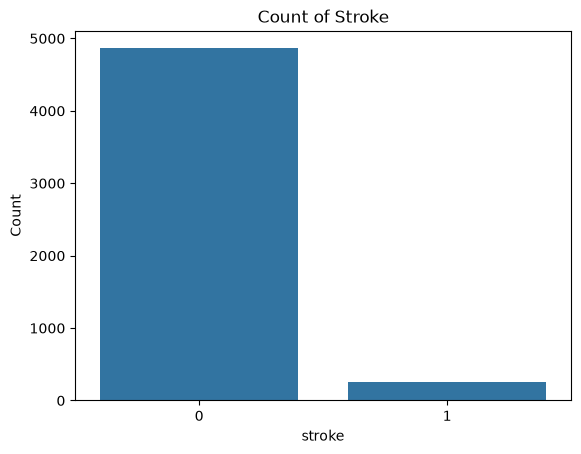

stroke
0    4861
1     249
Name: count, dtype: int64


In [6]:
sns.countplot(data=df, x='stroke')
plt.title('Count of Stroke')
plt.xlabel('stroke')
plt.ylabel('Count')
plt.show()

print(df['stroke'].value_counts())

### 2.2 Countplots with `hue='stroke'` for `gender`, `work_type`, `smoking_status` using subplots

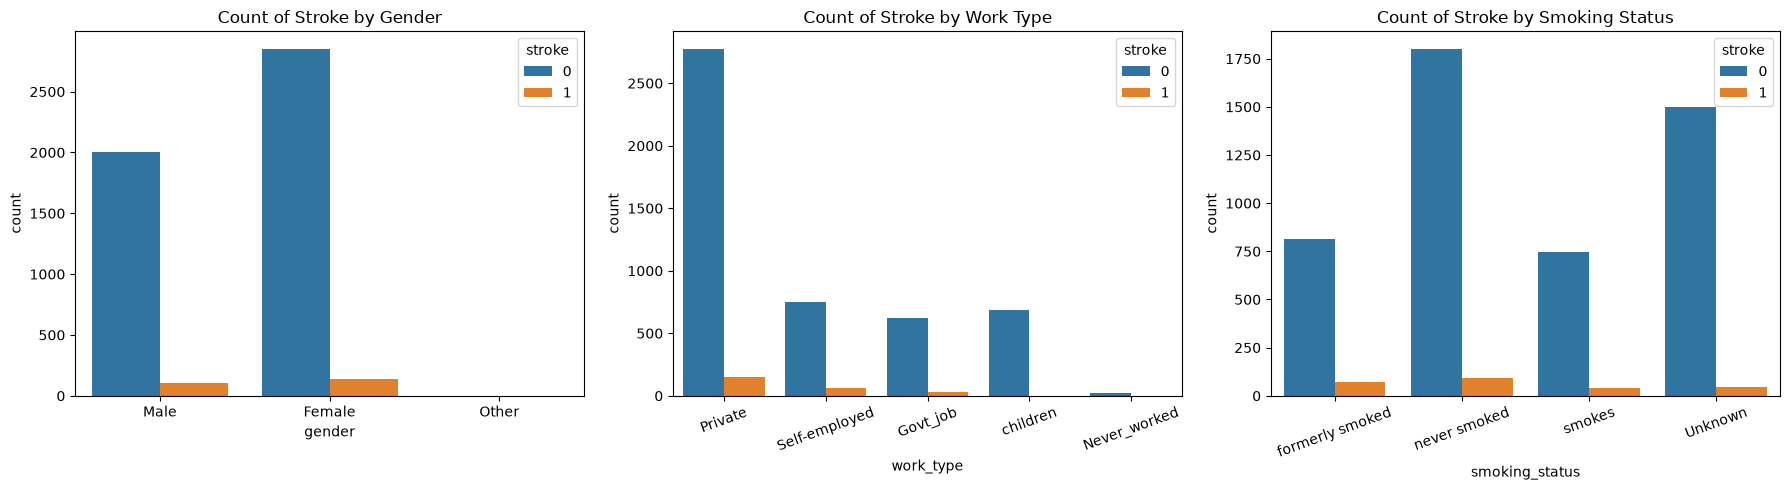

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=df, x='gender', hue='stroke', ax=axes[0])
axes[0].set_title('Count of Stroke by Gender')

sns.countplot(data=df, x='work_type', hue='stroke', ax=axes[1])
axes[1].set_title('Count of Stroke by Work Type')
axes[1].tick_params(axis='x', rotation=20)

sns.countplot(data=df, x='smoking_status', hue='stroke', ax=axes[2])
axes[2].set_title('Count of Stroke by Smoking Status')
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

### 2.3 Drop the 'Other' gender record (only 1 exists)

In [8]:
print(df['gender'].value_counts())

df = df[df['gender'] != 'Other']

print('After dropping Other:')
print(df['gender'].value_counts())

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
After dropping Other:
gender
Female    2994
Male      2115
Name: count, dtype: int64


### 2.4 Histograms / KDE plots for `age`, `avg_glucose_level`, `bmi` using subplots

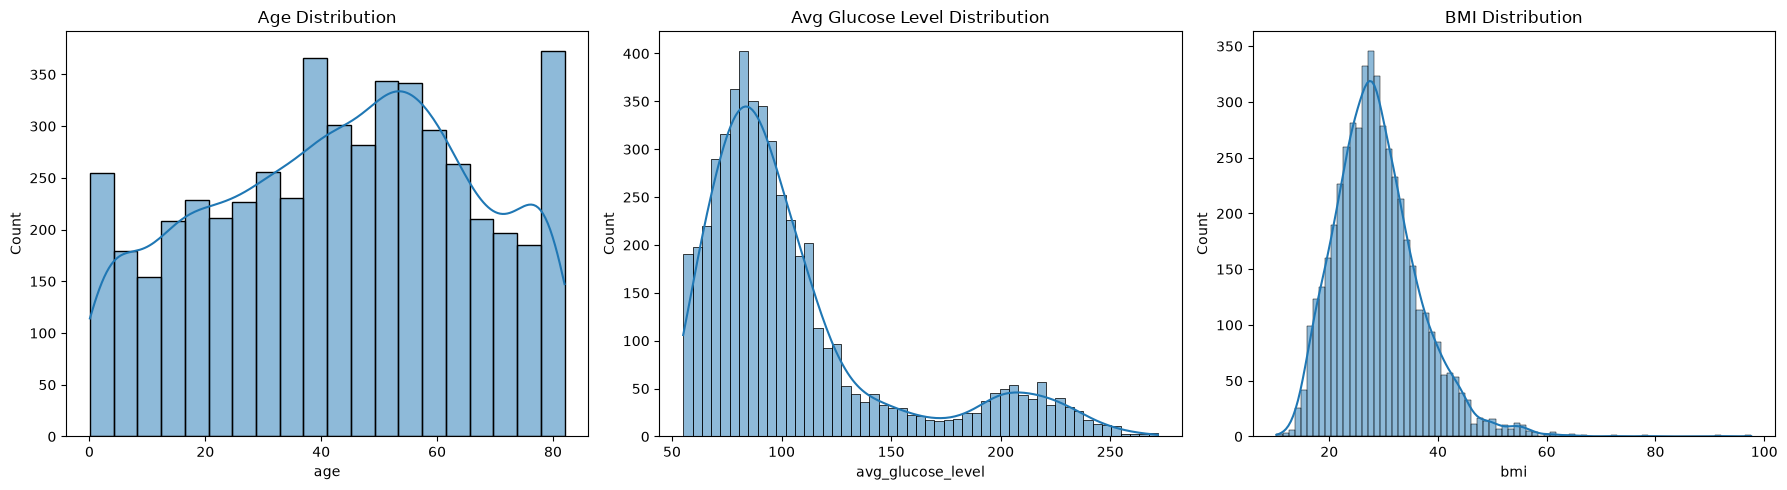

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=df, x='age', kde=True, ax=axes[0])
axes[0].set_title('Age Distribution')
sns.histplot(data=df, x='avg_glucose_level', kde=True, ax=axes[1])
axes[1].set_title('Avg Glucose Level Distribution')
sns.histplot(data=df, x='bmi', kde=True, ax=axes[2])
axes[2].set_title('BMI Distribution')

plt.tight_layout()
plt.show()

### 2.5 Correlation heatmap of selected numerical features and `stroke`

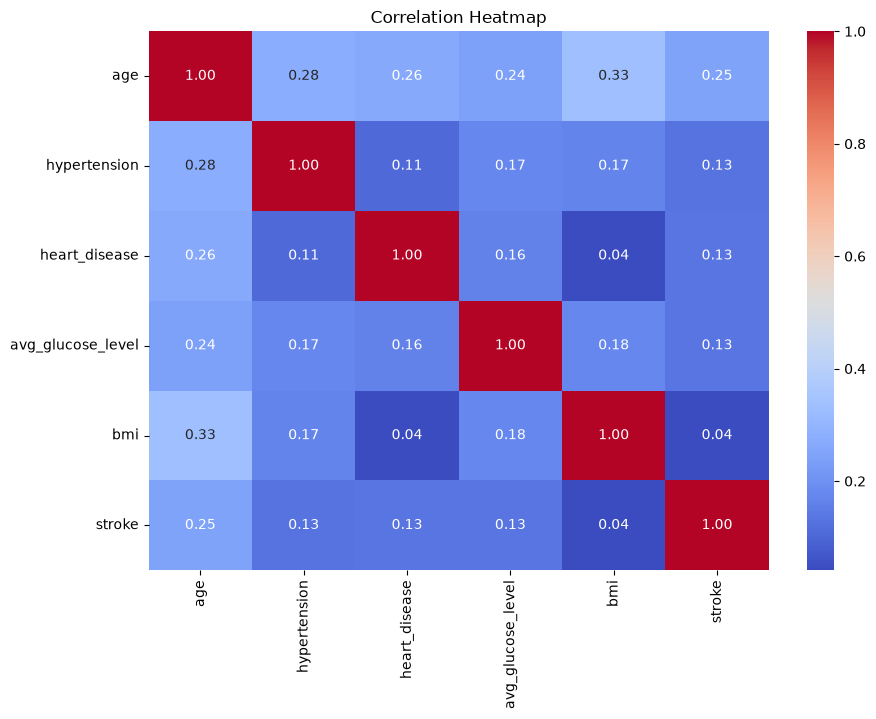

In [10]:
numerical_cols = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']

plt.figure(figsize=(10, 7))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

### Extra: Age distribution by stroke status

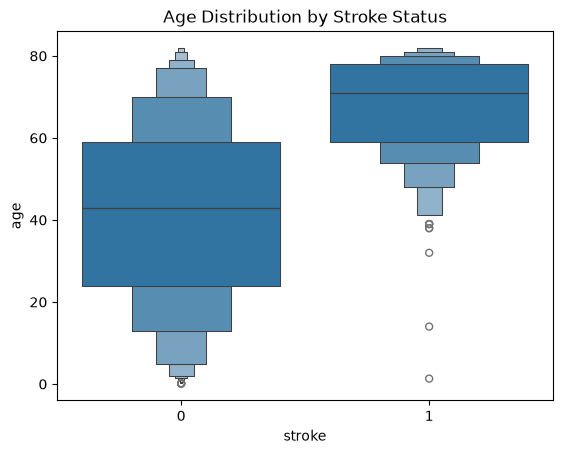

In [11]:
sns.boxenplot(data=df, x='stroke', y='age')
plt.title('Age Distribution by Stroke Status')
plt.ylabel('age')
plt.xlabel('stroke')
plt.show()

## Part 3: Data Preprocessing (Cleaning)

### 3.1 Check for missing values using `df.isnull().sum()`

In [12]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

### 3.2 Fill `bmi` missing values using the mean

In [13]:
df['bmi'] = df['bmi'].fillna(df['bmi'].mean())

### 3.3 Verify no missing values remain

In [14]:
print(df.isnull().sum())
print('Total missing values:', df.isnull().sum().sum())

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64
Total missing values: 0


### 3.4 Check for duplicates and remove them if any exist

In [15]:
print('Duplicates:', df.duplicated().sum())
df = df.drop_duplicates()
print('Shape after removing duplicates:', df.shape)

Duplicates: 0
Shape after removing duplicates: (5109, 12)


### 3.5 Drop `id` (no predictive power)

In [16]:
df = df.drop(columns=['id'])
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.60000,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.89456,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.50000,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.40000,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.00000,never smoked,1


### 3.6 Boxplot for `avg_glucose_level` to detect outliers (and remove if needed)

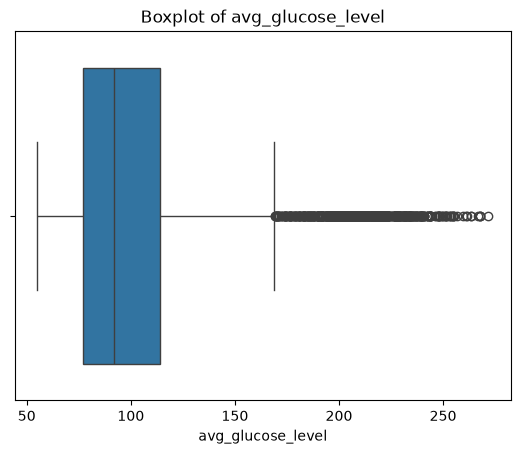

In [17]:
sns.boxplot(data=df, x='avg_glucose_level')
plt.title('Boxplot of avg_glucose_level')
plt.show()

In [18]:
Q1 = df['avg_glucose_level'].quantile(0.25)
Q3 = df['avg_glucose_level'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['avg_glucose_level'] < lower_bound) | (df['avg_glucose_level'] > upper_bound)]

print('Lower bound:', round(lower_bound, 2), '| Upper bound:', round(upper_bound, 2))
print('Number of outliers:', len(outliers))
print('Stroke rate inside outliers:', round(outliers['stroke'].mean() * 100, 1), '%')
print('Stroke rate overall:', round(df['stroke'].mean() * 100, 1), '%')

Lower bound: 21.96 | Upper bound: 169.36
Number of outliers: 627
Stroke rate inside outliers: 13.4 %
Stroke rate overall: 4.9 %


**Decision:** the outliers are kept. High glucose values are real medical readings (diabetic patients), and the stroke rate among them is much higher than average, so removing them would delete exactly the high-risk patients we want the model to learn from.

## Part 4: Feature Transformation

### 4.1 Categorical variables to encode: `gender`, `work_type`, `smoking_status`, `ever_married`, `Residence_type`

In [19]:
categorical_cols = ['gender', 'work_type', 'smoking_status', 'ever_married', 'Residence_type']

df[categorical_cols].nunique()

gender            2
work_type         5
smoking_status    4
ever_married      2
Residence_type    2
dtype: int64

### 4.2 Reset DataFrame index

In [20]:
df = df.reset_index(drop=True)
df.tail()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5104,Female,80.0,1,0,Yes,Private,Urban,83.75,28.89456,never smoked,0
5105,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.00000,never smoked,0
5106,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.60000,never smoked,0
5107,Male,51.0,0,0,Yes,Private,Rural,166.29,25.60000,formerly smoked,0
5108,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.20000,Unknown,0


### 4.3 Apply one-hot encoding using `pd.get_dummies()`

In [21]:
df = pd.get_dummies(df, columns=categorical_cols, dtype=int)

print(df.shape)
df.head()

(5109, 21)


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,work_type_Govt_job,work_type_Never_worked,...,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,ever_married_No,ever_married_Yes,Residence_type_Rural,Residence_type_Urban
0,67.0,0,1,228.69,36.60000,1,0,1,0,0,...,0,0,0,1,0,0,0,1,0,1
1,61.0,0,0,202.21,28.89456,1,1,0,0,0,...,1,0,0,0,1,0,0,1,1,0
2,80.0,0,1,105.92,32.50000,1,0,1,0,0,...,0,0,0,0,1,0,0,1,1,0
3,49.0,0,0,171.23,34.40000,1,1,0,0,0,...,0,0,0,0,0,1,0,1,0,1
4,79.0,1,0,174.12,24.00000,1,1,0,0,0,...,1,0,0,0,1,0,0,1,1,0


## Part 5: Data Splitting

### 5.1 Separate features `X` and target `y`

In [22]:
X = df.drop('stroke', axis=1)
y = df['stroke']

### 5.2 `train_test_split()` with 80/20 ratio and `random_state=42`

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

### 5.3 Verify shapes of `X_train`, `X_test`, `y_train`, `y_test`

In [24]:
print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (4087, 20)
X_test: (1022, 20)
y_train: (4087,)
y_test: (1022,)


## Part 6: Feature Scaling
Scaler is fit on the training data only, then used to transform both train and test (avoids data leakage).

### 6.1 Import `StandardScaler`

In [25]:
from sklearn.preprocessing import StandardScaler

### 6.2 & 6.3 Scale `age`, `avg_glucose_level`, `bmi`: fit on train only, transform train and test

In [26]:
numerical_features = ['age', 'avg_glucose_level', 'bmi']

scaler = StandardScaler()

X_train[numerical_features] = scaler.fit_transform(X_train[numerical_features])
X_test[numerical_features] = scaler.transform(X_test[numerical_features])

X_train[numerical_features].describe().round(2)

,age,avg_glucose_level,bmi
count,4087.00,4087.00,4087.00
mean,-0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-1.91,-1.13,-2.40
25%,-0.81,-0.64,-0.66
50%,0.08,-0.31,-0.06
75%,0.78,0.18,0.51
max,1.71,3.71,8.88


## Part 7: Handling Class Imbalance

### 7.1 Check the distribution of `stroke` (training set)

stroke
0    3888
1     199
Name: count, dtype: int64


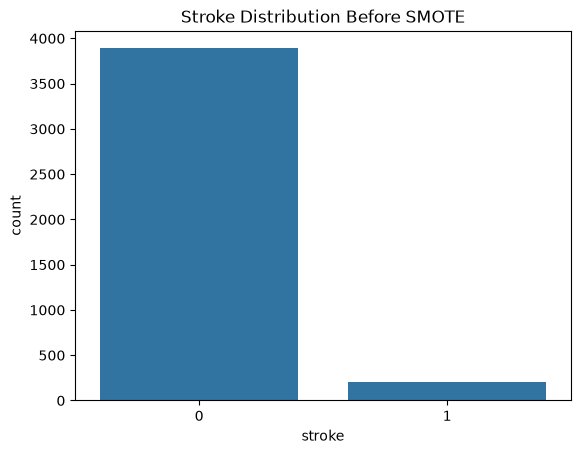

In [27]:
print(y_train.value_counts())

sns.countplot(x=y_train)
plt.title('Stroke Distribution Before SMOTE')
plt.show()

### 7.2 Apply SMOTE (training set only)

In [28]:
smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

### 7.3 Verify balanced distribution

stroke
0    3888
1    3888
Name: count, dtype: int64


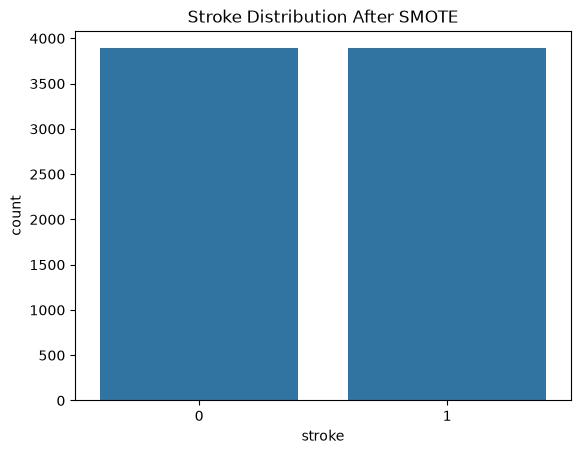

In [29]:
print(y_train_resampled.value_counts())

sns.countplot(x=y_train_resampled)
plt.title('Stroke Distribution After SMOTE')
plt.show()

### Numbers used in the conclusion

In [30]:
# numbers used in the conclusion
raw = pd.read_csv('healthcare-dataset-stroke-data.csv')
raw = raw[raw['gender'] != 'Other']
s, n = raw[raw.stroke == 1], raw[raw.stroke == 0]
print('Median age  -> stroke:', s.age.median(), '| no stroke:', n.age.median())
print('Hypertension-> stroke:', round(s.hypertension.mean()*100,1), '% | no stroke:', round(n.hypertension.mean()*100,1), '%')
print('Heart dis.  -> stroke:', round(s.heart_disease.mean()*100,1), '% | no stroke:', round(n.heart_disease.mean()*100,1), '%')
print('Avg glucose -> stroke:', round(s.avg_glucose_level.mean(),1), '| no stroke:', round(n.avg_glucose_level.mean(),1))
print('Mean BMI    -> stroke:', round(s.bmi.mean(),1), '| no stroke:', round(n.bmi.mean(),1))
print('Married     -> stroke:', round((s.ever_married=='Yes').mean()*100,1), '%')
print(s.smoking_status.value_counts(normalize=True).round(3))

Median age  -> stroke: 71.0 | no stroke: 43.0
Hypertension-> stroke: 26.5 % | no stroke: 8.9 %
Heart dis.  -> stroke: 18.9 % | no stroke: 4.7 %
Avg glucose -> stroke: 132.5 | no stroke: 104.8
Mean BMI    -> stroke: 30.5 | no stroke: 28.8
Married     -> stroke: 88.4 %
smoking_status
never smoked       0.361
formerly smoked    0.281
Unknown            0.189
smokes             0.169
Name: proportion, dtype: float64


## Conclusion

### High-Risk Stroke Patient Persona
**"Mr. Hassan", 72 years old**: married, retired from a private-sector job, has **hypertension** and **heart disease**, an average glucose level above **170 mg/dL** (likely diabetic), a BMI around **30** (overweight), and is a **former smoker**.

### Summary of Findings
1. **Severe class imbalance:** only **249 of 5,110** patients (**4.9%**) had a stroke, so accuracy alone would be misleading. SMOTE on the training set balanced it to **3,888 vs 3,888**.
2. **Age is the strongest factor:** median age of stroke patients is **71** vs **43** for others (highest correlation with stroke in the heatmap).
3. **Hypertension** is about 3x more common in stroke patients (**26.5% vs 8.9%**) and **heart disease** about 4x (**18.9% vs 4.7%**).
4. **Glucose:** stroke patients average **132.5** vs **104.8** mg/dL. The **627** patients above the IQR upper bound (**169.4**) have a **13.4%** stroke rate vs **4.9%** overall, so the outliers were **kept** as real, informative readings.
5. **BMI** is only slightly higher in stroke patients (**30.5 vs 28.8**), a weak predictor on its own.
6. **ever_married / work_type** look linked to stroke mostly because they follow age (**88.4%** of stroke patients were married), not as direct causes.
7. **Cleaning:** 201 missing `bmi` values filled with the mean, 0 duplicates found, the single `Other` gender row and the `id` column dropped.
8. **Final data:** 20 features after one-hot encoding, 80/20 stratified split (**4,087 train / 1,022 test**), `age`, `avg_glucose_level`, `bmi` scaled with StandardScaler fit on train only. The data is ready for modeling.